# Problem 3 — Compact publication results

1. **Figure 1:** mean PGM error for all five input states, using Exhaustive only.
2. **Figure 2:** grouped bars of mean error gaps for Greedy, VND, Near-Uniform, and Random relative to Exhaustive, for each input state.

Each figure contains 1D and 2D panels. Figures combine all selected instances. Numerical tables report overall and field-family summaries. Full mode includes every instance in the ordinary-random dataset; test mode selects a balanced subset.

Greedy allocates sensors to the least-separated field pair. VND independently starts near uniformly and maximizes the capped phase-separation score using transfers of one, two, and three sensors until convergence (tolerance $10^{-12}$). Neither heuristic evaluates PGM during allocation. Each returns one allocation per instance and budget, shared across all five states. Final comparisons use the unchanged global PGM error. Exhaustive is the Compact reference, optimal over allocations for the specified state and PGM measurement.

In [1]:
from pathlib import Path
import sys, importlib, json
from collections import Counter
from IPython.display import display, Markdown
ROOT = Path.cwd().resolve()
if (ROOT/'problem-3-global-pgm').is_dir(): ROOT = ROOT/'problem-3-global-pgm'
assert (ROOT/'src/pgm.py').exists()
loaded = sys.modules.get('src')
if loaded and Path(loaded.__file__).resolve().parent != ROOT/'src':
    raise RuntimeError('Restart kernel: another problem uses the src package')
for name in list(sys.modules):
    if name=='src' or name.startswith('src.'): del sys.modules[name]
sys.path.insert(0,str(ROOT))
importlib.invalidate_caches()
from src.analysis import METHODS, run_analysis, select_cases
from src.reporting.publication import prepare, figures
STUDY = 'compact'
DATASET_ROOT = ROOT/'inputs'/STUDY
RUN_MODE = 'full'       # 'full' uses all cases; 'test' uses a balanced sample.
RUN_ANALYSIS = True
RESUME = True
MAX_ALLOCATIONS = 20_000  # Compact maximum is C(20,4)=4845; unused by Extended.
TIME_LIMIT_SECONDS = 120.0
BOOTSTRAP_SEED = 20261014
BOOTSTRAP_RESAMPLES = 2000
SHOW_ZOOM = True
INCLUDE_REFERENCE_BASELINES = True


## Execution

Results are written to `results/compact/full/` or `results/extended/full/` (and separate `test/` folders). A fresh run overwrites the previous results for that study and mode. With `RESUME=True`, matching saved search records are reused and only missing runs are evaluated. Setting `RUN_ANALYSIS=False` loads matching saved results for reporting only. Plotting changes do not change the search cache signature; production source, dataset, and execution settings must still match.

Reference allocations are enabled by default. Near-Uniform and Random (one seeded allocation per instance and budget, assigning each sensor independently to a uniformly chosen location) appear in the second figure and summary tables. They are reference baselines, not optimization algorithms.


In [2]:
import matplotlib.pyplot as plt

records, OUTPUT = run_analysis(
    STUDY, RUN_MODE, run=RUN_ANALYSIS, resume=RESUME,
    max_allocations=MAX_ALLOCATIONS, time_limit=TIME_LIMIT_SECONDS,
    dataset_root=DATASET_ROOT, include_baselines=INCLUDE_REFERENCE_BASELINES,
)
PUBLICATION_OUTPUT = OUTPUT / 'publication_greedy_vnd'
print('Preparing confidence intervals and summary tables...', flush=True)
report = prepare(records, STUDY, PUBLICATION_OUTPUT,
                 seed=BOOTSTRAP_SEED, resamples=BOOTSTRAP_RESAMPLES)
print('Publication output:', PUBLICATION_OUTPUT)


compact full: 1D, 1350 cases
Snapshot 1/1350 | 1D | gaussian | K=3, M=3
Snapshot 2/1350 | 1D | gaussian | K=3, M=3
Snapshot 3/1350 | 1D | gaussian | K=3, M=3
Snapshot 4/1350 | 1D | gaussian | K=3, M=3
Snapshot 5/1350 | 1D | gaussian | K=3, M=3
Snapshot 6/1350 | 1D | gaussian | K=3, M=3
Snapshot 7/1350 | 1D | gaussian | K=3, M=3
Snapshot 8/1350 | 1D | gaussian | K=3, M=3
Snapshot 9/1350 | 1D | gaussian | K=3, M=3
Snapshot 10/1350 | 1D | gaussian | K=3, M=3
Snapshot 11/1350 | 1D | gaussian | K=3, M=3
Snapshot 12/1350 | 1D | gaussian | K=3, M=3
Snapshot 13/1350 | 1D | gaussian | K=3, M=3
Snapshot 14/1350 | 1D | gaussian | K=3, M=3
Snapshot 15/1350 | 1D | gaussian | K=3, M=3
Snapshot 16/1350 | 1D | gaussian | K=3, M=3
Snapshot 17/1350 | 1D | gaussian | K=3, M=3
Snapshot 18/1350 | 1D | gaussian | K=3, M=3
Snapshot 19/1350 | 1D | gaussian | K=3, M=3
Snapshot 20/1350 | 1D | gaussian | K=3, M=3
Snapshot 21/1350 | 1D | gaussian | K=3, M=3
Snapshot 22/1350 | 1D | gaussian | K=3, M=3
Snapshot 23/

## Estimation and confidence intervals

All intervals are **pointwise 95% percentile bootstrap confidence intervals** from 2,000 seeded resamples of field instances, stratified by the predefined benchmark design cells. Repeated budgets, states, and method comparisons from a field instance form one sampling unit. Intervals are conditional on the benchmark selection procedure, not simultaneous confidence bands or evidence of statistical significance.

Curve points group target fractions 25%, 50%, 75%, and 100%. Their x coordinates are mean actual ratios $N/N_{\mathrm{LB}}^{\mathrm{joint}}$, which need not equal the target fractions when caps or rounding apply. Duplicate integer budgets are evaluated once. Figures 2 and 4 average paired error differences over unique budgets within each field instance, separately for each input state, before averaging instances. Each field instance has equal weight.

State figures require all five states to complete for the specified reference method. Gap figures require all compared methods and states to complete at each field/budget. Missing or timed-out runs are excluded explicitly in the coverage table. Full mode is intended for publication; test mode may have singleton sampling strata and degenerate confidence intervals.

Figures use Times New Roman at 12 pt, consistent colors and markers, vector PDF with embedded fonts, and 600-dpi PNG export. The 10.8-inch figure width follows the two-panel layout used in Problem 2.

findfont: Failed to find font weight normal, now using 0.
findfont: Failed to find font weight normal, now using 0.


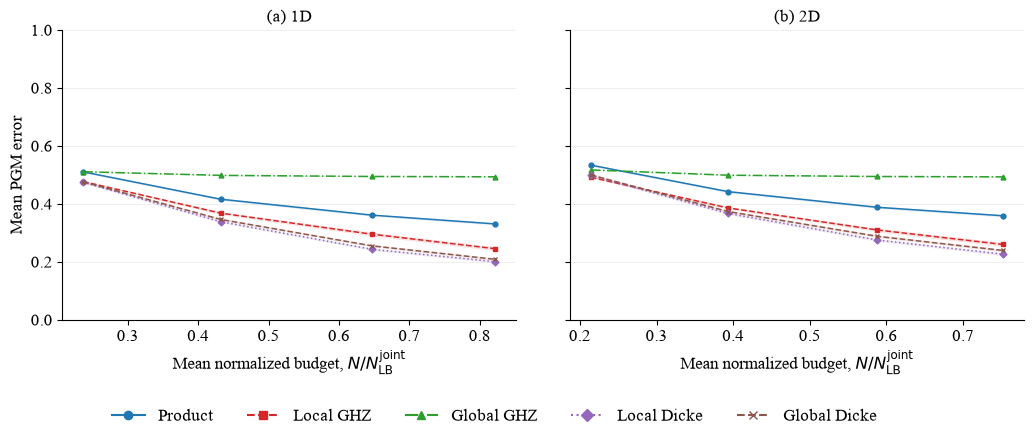

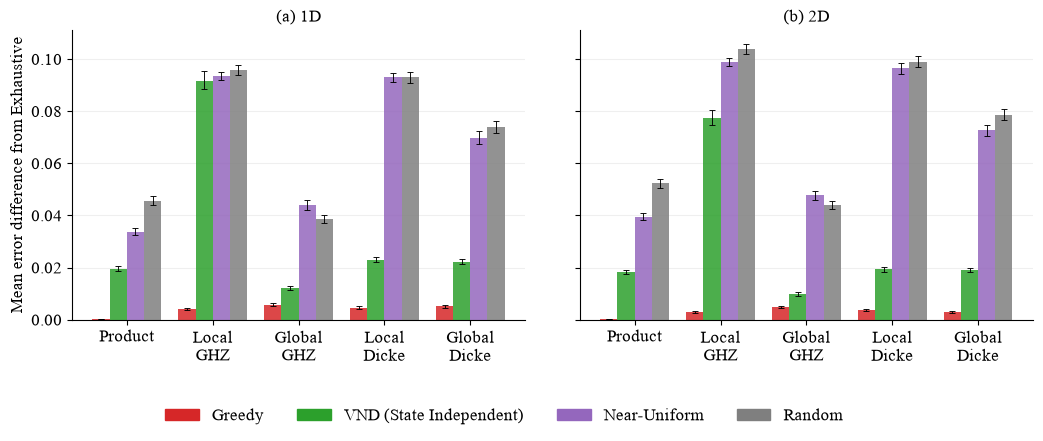

**Error bars:** 95% percentile bootstrap confidence intervals for the mean paired error difference from Exhaustive (2,000 resamples; field instances stratified by K, M, and field family). Budgets are averaged within each instance.

In [3]:
publication_figures = figures(report, STUDY, zoom=SHOW_ZOOM)
assert len(publication_figures) == 2
for figure in publication_figures:
    display(figure)
    plt.close(figure)

display(Markdown('**Error bars:** 95% percentile bootstrap confidence intervals for the mean paired error difference from Exhaustive (2,000 resamples; field instances stratified by K, M, and field family). Budgets are averaged within each instance.'))


## Numerical summaries

Tables summarize the complete benchmark and each field family separately. An optimality match means error within $10^{-7}$ of Exhaustive, not an identical allocation vector. VND wins, ties, or loses according to its paired error difference from Greedy with the same tolerance; percentages average unique budgets within each instance first. These comparisons remain available when Exhaustive is incomplete.

Runtime summaries separate allocation time per instance/budget from final PGM evaluation time per state. Allocation time is counted once across the five states; combined per-state time assigns one fifth of that cost to each state. Exhaustive reports its full enumeration/PGM search time separately because objective evaluation is intrinsic to its search. Runtime means describe successful runs; coverage and status CSVs retain excluded outcomes. Detailed figure coordinates, intervals, and table values are exported as CSV files.

In [4]:
def show_table(rows):
    if not rows: print('No complete results'); return
    keys=list(rows[0]);lines=['| '+' | '.join(keys)+' |','| '+' | '.join(['---']*len(keys))+' |']
    for row in rows:
        lines.append('| '+' | '.join(f'{row[k]:.6g}' if isinstance(row[k],float) else str(row[k]) for k in keys)+' |')
    display(Markdown('\n'.join(lines)))

In [5]:
for overall, heading in [(True, 'Overall summary'), (False, 'Field-family summary')]:
    display(Markdown('## '+heading))
    for key, title in [('quality', 'Error and gap summary'),
                       ('runtime', 'Runtime (seconds)'),
                       ('outcomes', 'VND versus Greedy')]:
        rows = [row for row in report[key] if (row['family'] == 'Overall') == overall]
        if overall:
            rows = [{k:v for k,v in row.items() if k != 'family'} for row in rows]
        display(Markdown('### '+title))
        show_table(rows)


## Overall summary

### Error and gap summary

| dimension | state | method | instances | mean_error | mean_gap | ci_low | ci_high | optimality_match_percent |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1D | Product | Greedy | 1350 | 0.3856 | 0.000311488 | 0.000246657 | 0.000382705 | 87.0926 |
| 1D | Product | VND (State Independent) | 1350 | 0.404913 | 0.0196245 | 0.018798 | 0.0204741 | 21.0864 |
| 1D | Product | Near-Uniform | 1350 | 0.419092 | 0.0338042 | 0.0324297 | 0.0351549 | 3.19136 |
| 1D | Product | Random | 1350 | 0.431002 | 0.0457133 | 0.0441633 | 0.047384 | 2.93827 |
| 1D | Local GHZ | Greedy | 1350 | 0.259227 | 0.00427367 | 0.00388071 | 0.0046739 | 71.6852 |
| 1D | Local GHZ | VND (State Independent) | 1350 | 0.34674 | 0.0917859 | 0.0886183 | 0.0952608 | 15.0309 |
| 1D | Local GHZ | Near-Uniform | 1350 | 0.348447 | 0.093493 | 0.0919953 | 0.0950179 | 2.65432 |
| 1D | Local GHZ | Random | 1350 | 0.350661 | 0.0957074 | 0.0938795 | 0.0977021 | 2.84568 |
| 1D | Global GHZ | Greedy | 1350 | 0.492669 | 0.00575685 | 0.00520061 | 0.00632865 | 30.3642 |
| 1D | Global GHZ | VND (State Independent) | 1350 | 0.499074 | 0.0121613 | 0.0113984 | 0.0129844 | 24.2469 |
| 1D | Global GHZ | Near-Uniform | 1350 | 0.530913 | 0.0440008 | 0.0421893 | 0.0459128 | 1.16049 |
| 1D | Global GHZ | Random | 1350 | 0.525552 | 0.0386396 | 0.0371524 | 0.0401818 | 2.35185 |
| 1D | Local Dicke | Greedy | 1350 | 0.296035 | 0.00463658 | 0.00412845 | 0.00513743 | 74.3951 |
| 1D | Local Dicke | VND (State Independent) | 1350 | 0.314475 | 0.0230762 | 0.0221427 | 0.0239801 | 37.0741 |
| 1D | Local Dicke | Near-Uniform | 1350 | 0.384396 | 0.0929979 | 0.0911055 | 0.0948328 | 1.70988 |
| 1D | Local Dicke | Random | 1350 | 0.384346 | 0.092948 | 0.0909881 | 0.094991 | 2.30247 |
| 1D | Global Dicke | Greedy | 1350 | 0.304696 | 0.00508687 | 0.00453136 | 0.00565764 | 66.8457 |
| 1D | Global Dicke | VND (State Independent) | 1350 | 0.321893 | 0.0222843 | 0.0213173 | 0.0233298 | 32.6605 |
| 1D | Global Dicke | Near-Uniform | 1350 | 0.369513 | 0.069904 | 0.0675219 | 0.0722462 | 1.83951 |
| 1D | Global Dicke | Random | 1350 | 0.373702 | 0.0740927 | 0.0718237 | 0.0764043 | 2.31481 |
| 2D | Product | Greedy | 1350 | 0.413135 | 0.00028092 | 0.000197742 | 0.000368453 | 90.4753 |
| 2D | Product | VND (State Independent) | 1350 | 0.43105 | 0.018196 | 0.0174508 | 0.0189139 | 21.3827 |
| 2D | Product | Near-Uniform | 1350 | 0.452436 | 0.0395827 | 0.0382389 | 0.040901 | 3.83333 |
| 2D | Product | Random | 1350 | 0.465189 | 0.0523351 | 0.0506231 | 0.0540036 | 3.33333 |
| 2D | Local GHZ | Greedy | 1350 | 0.28785 | 0.00313439 | 0.00276953 | 0.00351476 | 79.3086 |
| 2D | Local GHZ | VND (State Independent) | 1350 | 0.362247 | 0.0775321 | 0.0747806 | 0.0803884 | 21.0432 |
| 2D | Local GHZ | Near-Uniform | 1350 | 0.383595 | 0.0988801 | 0.0972887 | 0.100437 | 3.08025 |
| 2D | Local GHZ | Random | 1350 | 0.388699 | 0.103984 | 0.10199 | 0.105903 | 3.28395 |
| 2D | Global GHZ | Greedy | 1350 | 0.49604 | 0.00501414 | 0.00457649 | 0.00545373 | 36.0864 |
| 2D | Global GHZ | VND (State Independent) | 1350 | 0.500794 | 0.00976829 | 0.00909863 | 0.0104644 | 28.9136 |
| 2D | Global GHZ | Near-Uniform | 1350 | 0.538752 | 0.0477259 | 0.0460455 | 0.049421 | 1.34568 |
| 2D | Global GHZ | Random | 1350 | 0.534949 | 0.0439233 | 0.0423948 | 0.04546 | 2.33333 |
| 2D | Local Dicke | Greedy | 1350 | 0.326464 | 0.00380922 | 0.00335489 | 0.00428569 | 79.3457 |
| 2D | Local Dicke | VND (State Independent) | 1350 | 0.342013 | 0.0193579 | 0.0184838 | 0.0201728 | 42.284 |
| 2D | Local Dicke | Near-Uniform | 1350 | 0.419057 | 0.0964023 | 0.0944681 | 0.0983635 | 2.14198 |
| 2D | Local Dicke | Random | 1350 | 0.421576 | 0.0989211 | 0.0968252 | 0.10119 | 2.68519 |
| 2D | Global Dicke | Greedy | 1350 | 0.334199 | 0.00288966 | 0.00250509 | 0.00328963 | 74.1852 |
| 2D | Global Dicke | VND (State Independent) | 1350 | 0.350477 | 0.0191677 | 0.0183253 | 0.0200252 | 34.4012 |
| 2D | Global Dicke | Near-Uniform | 1350 | 0.403937 | 0.072628 | 0.0706024 | 0.0747729 | 2.04938 |
| 2D | Global Dicke | Random | 1350 | 0.409996 | 0.0786871 | 0.0765169 | 0.0809814 | 2.71605 |

### Runtime (seconds)

| dimension | method | completed | attempted | allocation_runs | mean_allocation_seconds | mean_final_pgm_seconds | mean_exhaustive_search_seconds | mean_seconds | median_seconds | total_observed_seconds |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1D | Exhaustive | 26890 | 26890 | 0 | None | None | 0.0700372 | 0.0700372 | 0.00782104 | 1883.3 |
| 1D | Greedy | 26890 | 26890 | 26890 | 0.00350346 | 0 | 0.00350346 | 0.00350346 | 0.00258129 | 94.2079 |
| 1D | VND (State Independent) | 26890 | 26890 | 5378 | 0.000225229 | 0.000141517 | None | 0.000186562 | 0.000158326 | 5.01666 |
| 1D | Near-Uniform | 26890 | 26890 | 5378 | 3.47717e-06 | 0.000151831 | None | 0.000152526 | 0.000105937 | 4.10143 |
| 1D | Random | 26890 | 26890 | 5378 | 3.85006e-05 | 0.000143173 | None | 0.000150873 | 0.000111517 | 4.05697 |
| 2D | Exhaustive | 26885 | 26885 | 0 | None | None | 0.0794263 | 0.0794263 | 0.00828438 | 2135.38 |
| 2D | Greedy | 26885 | 26885 | 26885 | 0.00363949 | 0 | 0.00363949 | 0.00363949 | 0.00262863 | 97.8477 |
| 2D | VND (State Independent) | 26885 | 26885 | 5377 | 0.000231728 | 0.000142698 | None | 0.000189044 | 0.000158649 | 5.08244 |
| 2D | Near-Uniform | 26885 | 26885 | 5377 | 3.36148e-06 | 0.000149316 | None | 0.000149988 | 0.000105592 | 4.03243 |
| 2D | Random | 26885 | 26885 | 5377 | 3.59334e-05 | 0.000144293 | None | 0.00015148 | 0.000110891 | 4.07254 |

### VND versus Greedy

... (4 outputs left out)

### Runtime (seconds)

| dimension | family | method | completed | attempted | allocation_runs | mean_allocation_seconds | mean_final_pgm_seconds | mean_exhaustive_search_seconds | mean_seconds | median_seconds | total_observed_seconds |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1D | gaussian | Exhaustive | 9000 | 9000 | 0 | None | None | 0.0706346 | 0.0706346 | 0.0110201 | 635.712 |
| 1D | gaussian | Greedy | 9000 | 9000 | 9000 | 0.00376701 | 0 | 0.00376701 | 0.00376701 | 0.00289715 | 33.9031 |
| 1D | gaussian | VND (State Independent) | 9000 | 9000 | 1800 | 0.000240976 | 0.000144711 | None | 0.000192907 | 0.000163983 | 1.73616 |
| 1D | gaussian | Near-Uniform | 9000 | 9000 | 1800 | 3.44919e-06 | 0.00014981 | None | 0.0001505 | 0.000105675 | 1.3545 |
| 1D | gaussian | Random | 9000 | 9000 | 1800 | 3.8158e-05 | 0.000145735 | None | 0.000153366 | 0.000110958 | 1.3803 |
| 1D | quadratic | Exhaustive | 9000 | 9000 | 0 | None | None | 0.114541 | 0.114541 | 0.0139937 | 1030.87 |
| 1D | quadratic | Greedy | 9000 | 9000 | 9000 | 0.0044535 | 0 | 0.0044535 | 0.0044535 | 0.00343683 | 40.0815 |
| 1D | quadratic | VND (State Independent) | 9000 | 9000 | 1800 | 0.00027684 | 0.000145732 | None | 0.0002011 | 0.000171325 | 1.8099 |
| 1D | quadratic | Near-Uniform | 9000 | 9000 | 1800 | 3.42363e-06 | 0.000157701 | None | 0.000158386 | 0.000105288 | 1.42547 |
| 1D | quadratic | Random | 9000 | 9000 | 1800 | 3.82639e-05 | 0.000153609 | None | 0.000161262 | 0.000110742 | 1.45136 |
| 1D | sinusoidal | Exhaustive | 8890 | 8890 | 0 | None | None | 0.0243777 | 0.0243777 | 0.00339198 | 216.717 |
| 1D | sinusoidal | Greedy | 8890 | 8890 | 8890 | 0.00227484 | 0 | 0.00227484 | 0.00227484 | 0.00169133 | 20.2233 |
| 1D | sinusoidal | VND (State Independent) | 8890 | 8890 | 1778 | 0.000157037 | 0.000134015 | None | 0.000165422 | 0.000143183 | 1.47061 |
| 1D | sinusoidal | Near-Uniform | 8890 | 8890 | 1778 | 3.55968e-06 | 0.000147934 | None | 0.000148646 | 0.000107038 | 1.32146 |
| 1D | sinusoidal | Random | 8890 | 8890 | 1778 | 3.90872e-05 | 0.000130013 | None | 0.000137831 | 0.000112667 | 1.22531 |
| 2D | gaussian | Exhaustive | 9000 | 9000 | 0 | None | None | 0.110004 | 0.110004 | 0.0143979 | 990.035 |
| 2D | gaussian | Greedy | 9000 | 9000 | 9000 | 0.00453135 | 0 | 0.00453135 | 0.00453135 | 0.00353287 | 40.7822 |
| 2D | gaussian | VND (State Independent) | 9000 | 9000 | 1800 | 0.000281555 | 0.000155954 | None | 0.000212265 | 0.000177671 | 1.91038 |
| 2D | gaussian | Near-Uniform | 9000 | 9000 | 1800 | 3.72779e-06 | 0.000163101 | None | 0.000163846 | 0.000108075 | 1.47462 |
| 2D | gaussian | Random | 9000 | 9000 | 1800 | 4.39655e-05 | 0.000157165 | None | 0.000165958 | 0.000114275 | 1.49362 |
| 2D | quadratic | Exhaustive | 9000 | 9000 | 0 | None | None | 0.118904 | 0.118904 | 0.014076 | 1070.13 |
| 2D | quadratic | Greedy | 9000 | 9000 | 9000 | 0.00454031 | 0 | 0.00454031 | 0.00454031 | 0.00347779 | 40.8628 |
| 2D | quadratic | VND (State Independent) | 9000 | 9000 | 1800 | 0.000282822 | 0.000145885 | None | 0.000202449 | 0.000172305 | 1.82204 |
| 2D | quadratic | Near-Uniform | 9000 | 9000 | 1800 | 3.2993e-06 | 0.000159615 | None | 0.000160275 | 0.000105075 | 1.44248 |
| 2D | quadratic | Random | 9000 | 9000 | 1800 | 3.54827e-05 | 0.000154794 | None | 0.000161891 | 0.000109946 | 1.45702 |
| 2D | sinusoidal | Exhaustive | 8885 | 8885 | 0 | None | None | 0.00846431 | 0.00846431 | 0.00296983 | 75.2054 |
| 2D | sinusoidal | Greedy | 8885 | 8885 | 8885 | 0.0018236 | 0 | 0.0018236 | 0.0018236 | 0.00145104 | 16.2027 |
| 2D | sinusoidal | VND (State Independent) | 8885 | 8885 | 1777 | 0.000129501 | 0.000126043 | None | 0.000151943 | 0.000133991 | 1.35002 |
| 2D | sinusoidal | Near-Uniform | 8885 | 8885 | 1777 | 3.05341e-06 | 0.00012492 | None | 0.00012553 | 0.000102866 | 1.11534 |
| 2D | sinusoidal | Random | 8885 | 8885 | 1777 | 2.8254e-05 | 0.000120618 | None | 0.000126269 | 0.00010645 | 1.1219 |

### VND versus Greedy

| dimension | family | state | case_budgets | win_percent | tie_percent | loss_percent |
| --- | --- | --- | --- | --- | --- | --- |
| 1D | gaussian | Product | 1800 | 1.22222 | 16.3333 | 82.4444 |
| 1D | gaussian | Local GHZ | 1800 | 2.88889 | 11.8889 | 85.2222 |
| 1D | gaussian | Global GHZ | 1800 | 18.1667 | 19.3889 | 62.4444 |
| 1D | gaussian | Local Dicke | 1800 | 10.3333 | 26.1111 | 63.5556 |
| 1D | gaussian | Global Dicke | 1800 | 10.2222 | 24.5 | 65.2778 |
| 1D | quadratic | Product | 1800 | 2.55556 | 18.6667 | 78.7778 |
| 1D | quadratic | Local GHZ | 1800 | 1.22222 | 14.1667 | 84.6111 |
| 1D | quadratic | Global GHZ | 1800 | 33.8333 | 27.8889 | 38.2778 |
| 1D | quadratic | Local Dicke | 1800 | 10.6111 | 43.5556 | 45.8333 |
| 1D | quadratic | Global Dicke | 1800 | 14.2778 | 30.8333 | 54.8889 |
| 1D | sinusoidal | Product | 1778 | 3 | 23.7222 | 73.2778 |
| 1D | sinusoidal | Local GHZ | 1778 | 4.37037 | 18.2593 | 77.3704 |
| 1D | sinusoidal | Global GHZ | 1778 | 14.5185 | 18.2963 | 67.1852 |
| 1D | sinusoidal | Local Dicke | 1778 | 9.48148 | 26.3148 | 64.2037 |
| 1D | sinusoidal | Global Dicke | 1778 | 10.6481 | 24.3889 | 64.963 |
| 2D | gaussian | Product | 1800 | 0.944444 | 18.4444 | 80.6111 |
| 2D | gaussian | Local GHZ | 1800 | 1.61111 | 23.1667 | 75.2222 |
| 2D | gaussian | Global GHZ | 1800 | 16 | 25.6111 | 58.3889 |
| 2D | gaussian | Local Dicke | 1800 | 4.11111 | 34.4444 | 61.4444 |
| 2D | gaussian | Global Dicke | 1800 | 5.83333 | 31.4444 | 62.7222 |
| 2D | quadratic | Product | 1800 | 2.72222 | 13.3889 | 83.8889 |
| 2D | quadratic | Local GHZ | 1800 | 1.55556 | 14.3333 | 84.1111 |
| 2D | quadratic | Global GHZ | 1800 | 35.5 | 29.4444 | 35.0556 |
| 2D | quadratic | Local Dicke | 1800 | 16.5556 | 44.3889 | 39.0556 |
| 2D | quadratic | Global Dicke | 1800 | 19.2778 | 24.1667 | 56.5556 |
| 2D | sinusoidal | Product | 1777 | 2.27778 | 28.037 | 69.6852 |
| 2D | sinusoidal | Local GHZ | 1777 | 3.66667 | 25.0926 | 71.2407 |
| 2D | sinusoidal | Global GHZ | 1777 | 14.1481 | 23.2963 | 62.5556 |
| 2D | sinusoidal | Local Dicke | 1777 | 7.33333 | 31.1667 | 61.5 |
| 2D | sinusoidal | Global Dicke | 1777 | 6.48148 | 29.3519 | 64.1667 |